# Módulo 8 · Aprendizaje automático con imágenes de células sanguíneas

**Versión resuelta para docentes.**

En esta clase recorremos el flujo completo del aprendizaje automático sobre un mismo conjunto de imágenes: clasificar, diagnosticar el sobreajuste, reducir la dimensión y agrupar sin etiquetas. Como en el módulo 7, nadie escribe código desde cero: se **pide** al asistente, se **lee** lo que generó, se **ejecuta** y se **verifica**.

| Bloque | Producto |
|---|---|
| 1. Imágenes y primer clasificador | Matriz de confusión interpretada |
| 2. Árbol, bosque y sobreajuste | Tabla de modelos y curva por profundidad |
| 3. Redes neuronales y curva de pérdida | Curva de pérdida con la época de parada marcada |
| 4. PCA y ablación | Figura de PCA y tabla de ablación |
| 5. Agrupamiento con K-Means | Tablas de grupos frente a tipos celulares |
| Cierre | Elección justificada de un modelo |

**Cómo trabajar con este cuaderno**

- Cada bloque empieza con un **ejemplo resuelto**. Después vienen las **consignas**: dicen qué se espera, no cómo pedirlo. El prompt lo escribís vos.
- Si te trabás, abrí la pista **¿Te trabaste?** que hay debajo de cada consigna.
- Anotá el prompt que usaste en el espacio **Tu prompt**: sirve para revisar después qué funcionó.
- Las consignas de **verificación** piden comprobar un resultado antes de seguir. No las saltees. Con imágenes hay una regla más: **antes de confiar en un resultado, mirá imágenes reales.**

## Sobre los datos

Trabajamos con **BloodMNIST**: 17 092 imágenes de microscopía de células normales de sangre periférica, tomadas con un analizador automático (CellaVision DM96) en el laboratorio central del Hospital Clínic de Barcelona y clasificadas por patólogos clínicos expertos. Las personas donantes no tenían infecciones ni enfermedades hematológicas u oncológicas, y no estaban bajo tratamiento farmacológico al momento de la extracción.

Las imágenes originales miden 360 × 363 píxeles. MedMNIST, la colección que publica esta versión, las recortó y las redujo a **28 × 28 píxeles en color**: se pierde detalle, pero cada imagen ocupa poco y los modelos se entrenan en segundos en cualquier computadora.

**Los ocho tipos celulares**

| Etiqueta | Tipo celular | Qué es |
|---|---|---|
| 0 | basófilo | Granulocito poco frecuente, con gránulos grandes y oscuros que tapan el núcleo. Libera histamina en las reacciones alérgicas. |
| 1 | eosinófilo | Granulocito con gránulos que se tiñen de anaranjado y núcleo de dos lóbulos. Interviene en alergias y en la defensa contra parásitos. |
| 2 | eritroblasto | Precursor del glóbulo rojo que todavía conserva el núcleo. |
| 3 | granulocito inmaduro | Precursores del neutrófilo (promielocito, mielocito y metamielocito), agrupados en una sola clase. |
| 4 | linfocito | Célula chica con un núcleo redondo que ocupa casi todo el citoplasma. Es la base de la inmunidad adaptativa. |
| 5 | monocito | El leucocito más grande, con núcleo en forma de riñón. En los tejidos se transforma en macrófago. |
| 6 | neutrófilo | El granulocito más abundante, con núcleo segmentado en varios lóbulos. Es la primera defensa contra bacterias. |
| 7 | plaqueta | No es una célula sino un fragmento sin núcleo. Interviene en la coagulación. |

**Cómo están organizados los datos.**

- El archivo trae tres **particiones** ya armadas: entrenamiento (11 959 imágenes), validación (1712) y prueba (3421).
- Cada imagen es un arreglo de 28 × 28 × 3 números enteros entre 0 y 255: la intensidad de rojo, verde y azul en cada píxel.
- Los tipos celulares no están balanceados: en entrenamiento hay de 849 linfocitos a 2330 neutrófilos. Por eso usamos una **submuestra balanceada de 5000 imágenes** (625 de cada tipo) y medimos con **F1 macro**, que pesa igual a todos los tipos.

**Más información.**

- **Página de MedMNIST:** [medmnist.github.io](https://medmnist.github.io/)
- **Fuente original:** Acevedo, A. et al. (2020). A dataset of microscopic peripheral blood cell images for development of automatic recognition systems. *Data in Brief*, 30, 105474.
- **Colección:** Yang, J. et al. (2023). MedMNIST v2. *Scientific Data*, 10, 41.
- **Descripción detallada, licencia (CC BY 4.0) y cómo descargarlo:** [`data/README.md`](../data/README.md) en la carpeta del curso.

## 0. Configuración

Esta es la **única celda** que nombra al conjunto de datos y fija los parámetros de la clase. El resto del cuaderno usa estos nombres.

In [3]:
# === Configuración del conjunto de datos ===

# De dónde salen los datos (el mismo archivo en dos lugares)
RUTA_NPZ = "../data/bloodmnist.npz"  # copia en la carpeta del curso (herramientas/descargar_bloodmnist.py)
URL_DATOS = "https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1"  # original publicado en Zenodo

# Qué hay dentro del archivo: para cada partición, las imágenes (variables de entrada)
# y las etiquetas (variable objetivo)
CLAVES = {
    "entrenamiento": ("train_images", "train_labels"),
    "validación": ("val_images", "val_labels"),
    "prueba": ("test_images", "test_labels"),
}

# Variable objetivo: el tipo celular, codificado de 0 a 7 en este orden
TIPOS_CELULARES = ["basófilo", "eosinófilo", "eritroblasto", "granulocito inmaduro",
                   "linfocito", "monocito", "neutrófilo", "plaqueta"]

# Bloque 1
IMAGENES_POR_TIPO = 625   # submuestra balanceada: 625 × 8 = 5000 imágenes de entrenamiento

# Bloque 2
PROFUNDIDADES = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20]  # profundidades máximas del árbol

# Bloque 3
NEURONAS = (100,)   # una capa oculta de 100 neuronas
EPOCAS = 40         # pasadas completas por los datos de entrenamiento

# Bloque 4
COMPONENTES = [2, 10, 50, 200]  # cantidades de componentes principales para la ablación

# Bloque 5
TIPOS_CONTRASTADOS = ["linfocito", "monocito", "neutrófilo", "plaqueta"]
COMPONENTES_AGRUPAMIENTO = 50   # componentes principales sobre las que trabaja K-Means
K_MAXIMO = 10                   # mayor cantidad de grupos que se prueba

SEMILLA = 42  # semilla fija: los resultados se repiten en cada ejecución

In [2]:
# Librerías que usa el cuaderno (con sus versiones en requirements.txt)
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, classification_report, ConfusionMatrixDisplay,
                             log_loss, adjusted_rand_score, silhouette_score)
from sklearn.exceptions import ConvergenceWarning

# La red del bloque 3 se entrena a propósito pocas épocas; este aviso diría que no terminó de converger
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## Bloque 1 · Imágenes y primer clasificador (30 min)

**Producto:** una matriz de confusión interpretada.

Un clasificador no ve una célula: ve una **tabla de números**. El primer paso es convertir cada imagen en una fila de esa tabla.

**Ejemplo resuelto.** Carga de las tres particiones. Si el archivo no está en la carpeta del curso, se descarga una vez desde Zenodo.

In [4]:
# Si el archivo no está en la carpeta del curso, se descarga (35 MB, una sola vez)
if not os.path.exists(RUTA_NPZ):
    os.makedirs(os.path.dirname(RUTA_NPZ), exist_ok=True)
    urllib.request.urlretrieve(URL_DATOS, RUTA_NPZ)

archivo = np.load(RUTA_NPZ)
imagenes_completo = archivo[CLAVES["entrenamiento"][0]]
y_completo = archivo[CLAVES["entrenamiento"][1]].ravel()  # ravel: de columna a lista de etiquetas
imagenes_val = archivo[CLAVES["validación"][0]]
y_val = archivo[CLAVES["validación"][1]].ravel()
imagenes_prueba = archivo[CLAVES["prueba"][0]]
y_prueba = archivo[CLAVES["prueba"][1]].ravel()

print("Entrenamiento completo:", imagenes_completo.shape)
print("Validación:            ", imagenes_val.shape)
print("Prueba:                ", imagenes_prueba.shape)

Entrenamiento completo: (11959, 28, 28, 3)
Validación:             (1712, 28, 28, 3)
Prueba:                 (3421, 28, 28, 3)


**Ejemplo resuelto.** Submuestra balanceada: 625 imágenes de cada tipo celular, elegidas al azar con la semilla fija. Todos los modelos de la clase se entrenan con estas 5000 imágenes.

In [5]:
generador = np.random.default_rng(SEMILLA)
indices = []
for tipo in range(len(TIPOS_CELULARES)):
    indices_del_tipo = np.flatnonzero(y_completo == tipo)
    indices.extend(generador.choice(indices_del_tipo, IMAGENES_POR_TIPO, replace=False))
indices = generador.permutation(indices)  # se mezclan para que no queden ordenadas por tipo

imagenes_entr = imagenes_completo[indices]
y_entr = y_completo[indices]
print("Submuestra de entrenamiento:", imagenes_entr.shape)

Submuestra de entrenamiento: (5000, 28, 28, 3)


**Ejemplo resuelto.** Una función para mirar imágenes, que vamos a usar en toda la clase. Recibe una lista de imágenes y, si se quiere, un título para cada una.

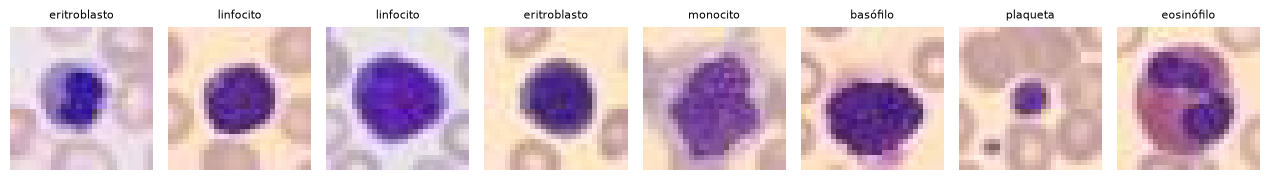

In [6]:
def mostrar_imagenes(imagenes, titulos=None, columnas=8, titulo_figura=None):
    """Muestra imágenes en una grilla, con un título opcional sobre cada una."""
    filas = int(np.ceil(len(imagenes) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(1.6 * columnas, 2.1 * filas), squeeze=False)
    for i, eje in enumerate(ejes.flat):
        eje.axis("off")
        if i < len(imagenes):
            if imagenes[i].ndim == 2:
                # Imagen en gris (un solo canal): escala fija de 0 a 255, sin estirar el contraste
                eje.imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
            else:
                eje.imshow(imagenes[i])
            if titulos is not None:
                eje.set_title(titulos[i], fontsize=8)
    if titulo_figura:
        fig.suptitle(titulo_figura)
    plt.tight_layout()
    plt.show()

mostrar_imagenes(imagenes_entr[:8], [TIPOS_CELULARES[t] for t in y_entr[:8]])

#### Consigna 1.1 · Conocer las células

Mostrá 6 imágenes de cada tipo celular de la submuestra de entrenamiento, con el nombre del tipo como título.

**Se espera:** una grilla de 8 filas (una por tipo celular) y 6 columnas. Antes de seguir, mirala con la tabla de tipos celulares de arriba: ¿reconocés el núcleo segmentado del neutrófilo, el núcleo redondo del linfocito, el tamaño chico de la plaqueta? ¿Qué tipos te parecen difíciles de distinguir a esta resolución?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Para cada tipo celular, buscá las primeras 6 imágenes cuya etiqueta en `y_entr` sea ese tipo. Juntá todas en una lista y pasala a `mostrar_imagenes` con `columnas=6`.

</details>

> **Prompt de referencia (docente)**
>
> Para cada tipo de `TIPOS_CELULARES`, tomá las primeras 6 imágenes de `imagenes_entr` con esa etiqueta en `y_entr` y mostralas todas con `mostrar_imagenes`, en 6 columnas, con el nombre del tipo como título de cada imagen.

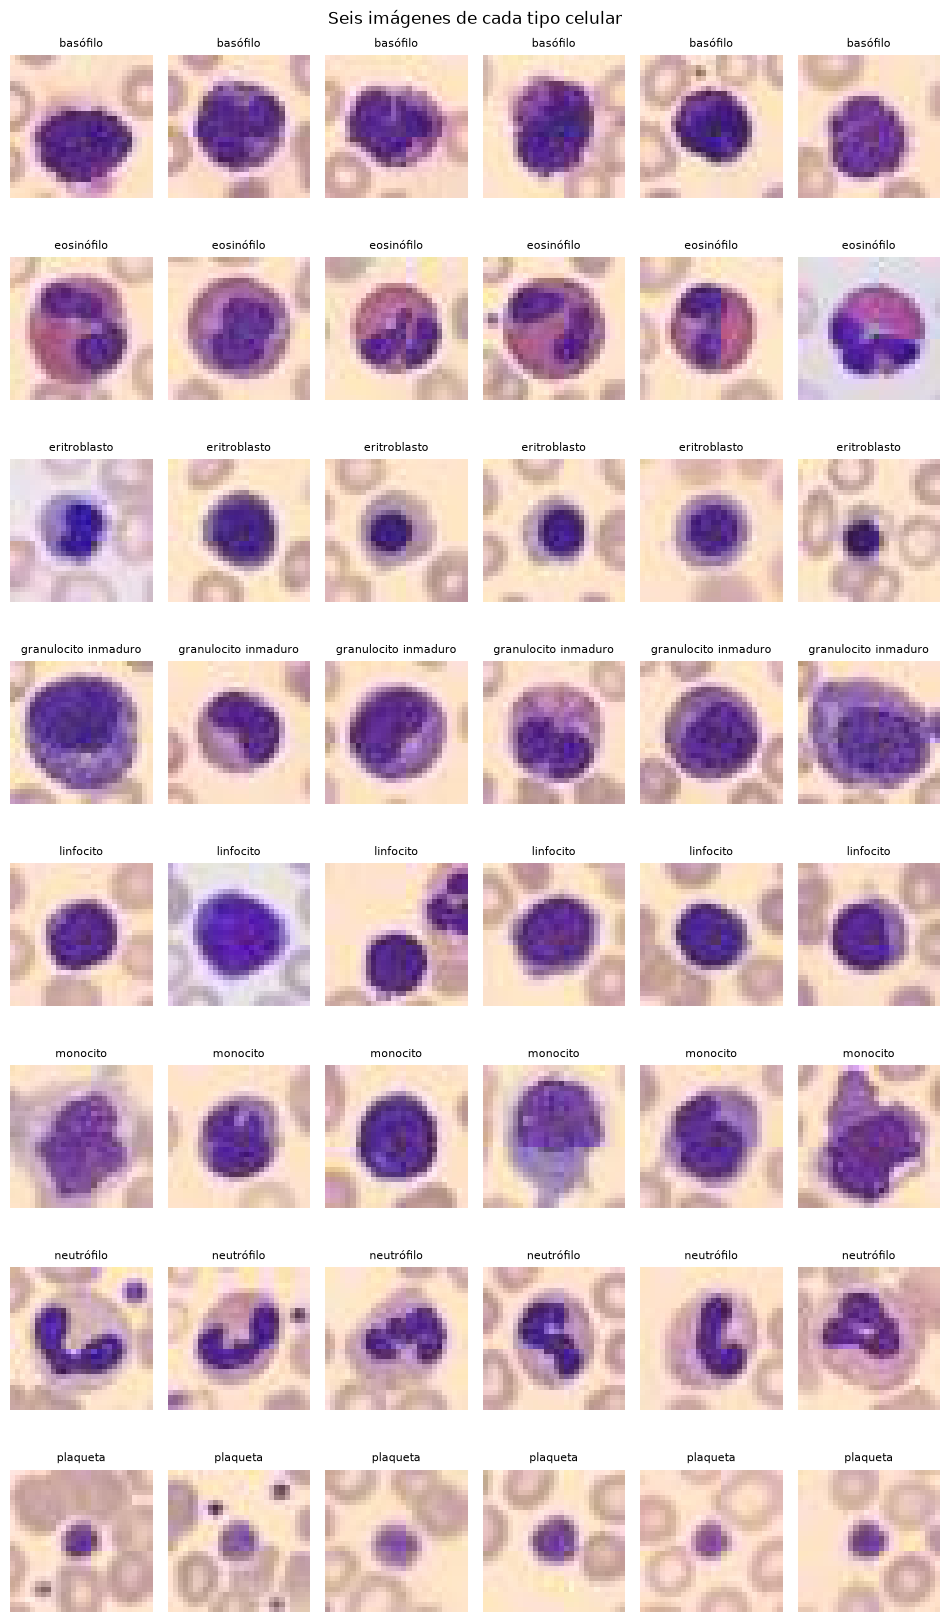

In [7]:
seleccion, titulos = [], []
for tipo, nombre in enumerate(TIPOS_CELULARES):
    for indice in np.flatnonzero(y_entr == tipo)[:6]:
        seleccion.append(imagenes_entr[indice])
        titulos.append(nombre)
mostrar_imagenes(seleccion, titulos, columnas=6, titulo_figura="Seis imágenes de cada tipo celular")

#### Consigna 1.2 · Verificación: ¿quedó balanceada?

Contá cuántas imágenes de cada tipo celular hay en la submuestra de entrenamiento y en la partición de prueba.

**Se espera:** una tabla con 8 filas y dos columnas. En entrenamiento, 625 en cada fila (5000 en total). En prueba, los conteos reales del archivo, que no están balanceados (3421 en total).

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Contar cuántas veces aparece cada etiqueta es una operación común en NumPy y en pandas. Usá `TIPOS_CELULARES` como nombres de las filas.

</details>

> **Prompt de referencia (docente)**
>
> Armá una tabla con una fila por tipo de `TIPOS_CELULARES` y dos columnas: cuántas imágenes de ese tipo hay en `y_entr` y cuántas en `y_prueba`. Agregá una fila con el total.

In [8]:
conteos = pd.DataFrame({
    "entrenamiento": np.bincount(y_entr, minlength=len(TIPOS_CELULARES)),
    "prueba": np.bincount(y_prueba, minlength=len(TIPOS_CELULARES)),
}, index=TIPOS_CELULARES)
conteos.loc["total"] = conteos.sum()
conteos

,entrenamiento,prueba
basófilo,625,244
eosinófilo,625,624
eritroblasto,625,311
granulocito inmaduro,625,579
linfocito,625,243
monocito,625,284
neutrófilo,625,666
plaqueta,625,470
total,5000,3421


**Ejemplo resuelto.** De imagen a tabla. Cada imagen de 28 × 28 píxeles con 3 canales se **aplana** en una fila de 28 × 28 × 3 = 2352 números, y se divide por 255 para que queden entre 0 y 1. Cada columna de la tabla es la intensidad de un color en un píxel.

Además preparamos una versión **estandarizada** de las tablas: cada columna con media 0 y desvío 1. Algunos modelos (la regresión logística, las redes) la necesitan; otros no, y lo vamos a ver a lo largo de la clase. El estandarizador aprende la media y el desvío **solo con los datos de entrenamiento** y después se aplica igual a validación y a prueba: si aprendiera de prueba, el modelo «espiaría» datos que no debe ver.

Por último, una lista `resultados` donde cada modelo va a anotar su F1. La usamos en el cierre.

In [9]:
def aplanar(imagenes):
    """Convierte imágenes de 28 × 28 × 3 en filas de 2352 valores entre 0 y 1."""
    return imagenes.reshape(len(imagenes), -1) / 255

X_entr = aplanar(imagenes_entr)
X_val = aplanar(imagenes_val)
X_prueba = aplanar(imagenes_prueba)
print("Tabla de entrenamiento:", X_entr.shape, "→ filas = imágenes, columnas = píxeles × canales")

# Versión estandarizada: media y desvío de cada columna calculados SOLO con entrenamiento
estandarizador = StandardScaler().fit(X_entr)
X_entr_est = estandarizador.transform(X_entr)
X_val_est = estandarizador.transform(X_val)
X_prueba_est = estandarizador.transform(X_prueba)

resultados = []  # cada modelo agrega aquí su F1 de entrenamiento y de prueba

Tabla de entrenamiento: (5000, 2352) → filas = imágenes, columnas = píxeles × canales


#### Consigna 1.3 · El primer clasificador

Entrená una **regresión logística** con la submuestra de entrenamiento estandarizada y evaluala en prueba.

**Se espera:**

- el F1 macro en entrenamiento y en prueba, con tres decimales;
- la **matriz de confusión** en prueba, con los nombres de los tipos celulares en los ejes;
- el resultado anotado en `resultados`.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

La regresión logística y la matriz de confusión están en scikit-learn. La regresión logística puede necesitar más iteraciones que las que trae por defecto. El F1 macro es el promedio del F1 de cada tipo celular.

</details>

> **Prompt de referencia (docente)**
>
> Entrená una `LogisticRegression(max_iter=1000)` llamada `logistica` con `X_entr_est` e `y_entr` y guardá sus predicciones sobre `X_prueba_est` en `prediccion_logistica`. Imprimí el F1 macro en entrenamiento y en prueba, mostrá la matriz de confusión en prueba con `TIPOS_CELULARES` como etiquetas y agregá a `resultados` un diccionario con el modelo y sus dos F1.

F1 macro · entrenamiento: 1.000 · prueba: 0.704


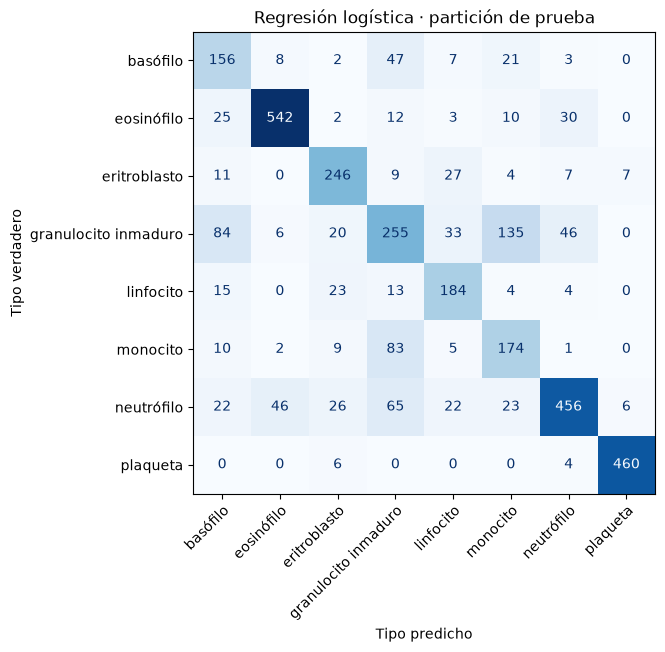

In [10]:
logistica = LogisticRegression(max_iter=1000).fit(X_entr_est, y_entr)
prediccion_logistica = logistica.predict(X_prueba_est)

f1_entr = f1_score(y_entr, logistica.predict(X_entr_est), average="macro")
f1_prueba = f1_score(y_prueba, prediccion_logistica, average="macro")
print(f"F1 macro · entrenamiento: {f1_entr:.3f} · prueba: {f1_prueba:.3f}")
resultados.append({"modelo": "regresión logística", "F1 entrenamiento": f1_entr, "F1 prueba": f1_prueba})

fig, eje = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_prueba, prediccion_logistica, display_labels=TIPOS_CELULARES,
                                        xticks_rotation=45, cmap="Blues", colorbar=False, ax=eje)
eje.set(title="Regresión logística · partición de prueba", xlabel="Tipo predicho", ylabel="Tipo verdadero")
plt.setp(eje.get_xticklabels(), ha="right", rotation_mode="anchor")  # etiquetas alineadas con su columna
plt.show()

#### Consigna 1.4 · Mirar los errores

Mostrá 16 imágenes de prueba que la regresión logística clasificó mal, cada una con su tipo verdadero y el predicho.

**Se espera:** una grilla de 16 imágenes con títulos del estilo «verdadero → predicho». Mirándolas: ¿los errores son comprensibles (células que se parecen) o absurdos?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Las imágenes mal clasificadas son aquellas donde la predicción no coincide con `y_prueba`. Para que el título entre en la imagen, conviene usar nombres cortos o dos renglones.

</details>

> **Prompt de referencia (docente)**
>
> Buscá las primeras 16 imágenes de `imagenes_prueba` donde `prediccion_logistica` no coincide con `y_prueba` y mostralas con `mostrar_imagenes`, con títulos «verdadero → predicho» en dos renglones.

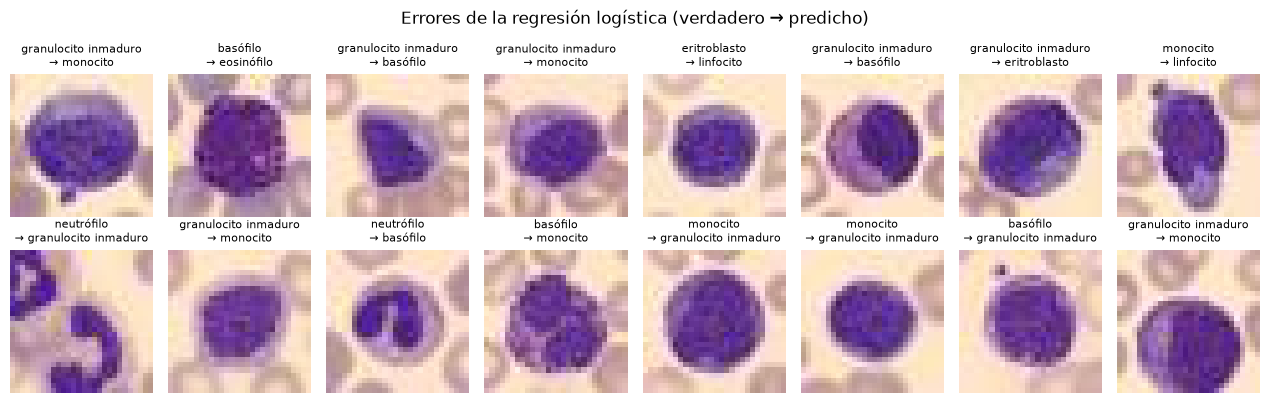

In [10]:
errores = np.flatnonzero(prediccion_logistica != y_prueba)[:16]
titulos = [f"{TIPOS_CELULARES[y_prueba[i]]}\n→ {TIPOS_CELULARES[prediccion_logistica[i]]}" for i in errores]
mostrar_imagenes(imagenes_prueba[errores], titulos, titulo_figura="Errores de la regresión logística (verdadero → predicho)")

#### Consigna 1.5 · Verificación: el recall a mano

El **recall** de un tipo celular es la fracción de sus imágenes que el modelo reconoció. Elegí un tipo y calculá su recall **a mano** con los números de su fila en la matriz de confusión (aciertos sobre total de la fila). Después pedí el reporte de clasificación de scikit-learn y comparalo.

**Se espera:** el reporte con precisión, recall y F1 de cada tipo celular, y que tu cuenta coincida con su recall en los dos primeros decimales.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

scikit-learn tiene una función que arma un reporte de clasificación con las métricas de cada clase. Pedí que use los nombres de los tipos celulares.

</details>

> **Prompt de referencia (docente)**
>
> Mostrá el reporte de clasificación de `prediccion_logistica` contra `y_prueba`, con `TIPOS_CELULARES` como nombres y tres decimales.

In [11]:
print(classification_report(y_prueba, prediccion_logistica, target_names=TIPOS_CELULARES, digits=3))

                      precision    recall  f1-score   support

            basófilo      0.483     0.639     0.550       244
          eosinófilo      0.897     0.869     0.883       624
        eritroblasto      0.737     0.791     0.763       311
granulocito inmaduro      0.527     0.440     0.480       579
           linfocito      0.655     0.757     0.702       243
            monocito      0.469     0.613     0.531       284
          neutrófilo      0.828     0.685     0.749       666
            plaqueta      0.973     0.979     0.976       470

            accuracy                          0.723      3421
           macro avg      0.696     0.722     0.704      3421
        weighted avg      0.734     0.723     0.725      3421



#### Interpretación

- La submuestra quedó balanceada: 625 imágenes de cada tipo celular, 5000 en total. La partición de prueba conserva el desbalance real del archivo, de 243 linfocitos a 666 neutrófilos (3421 en total).
- La regresión logística llega a un F1 macro de **1,000 en entrenamiento** y de **0,704 en prueba**. Con 2352 columnas tiene parámetros de sobra para separar sin error las 5000 imágenes que ya vio: las memoriza. Lo que vale es el F1 de prueba.
- Las **plaquetas** se reconocen casi siempre (recall 0,979): son mucho más chicas que cualquier célula. Los **eosinófilos** también (0,869), por el color anaranjado de sus gránulos.
- El tipo más difícil es el **granulocito inmaduro** (recall 0,440): de sus 579 imágenes de prueba, 135 se clasifican como monocito y 84 como basófilo. Le siguen el monocito (0,613) y el basófilo (0,639). Son células grandes, con un núcleo voluminoso, que a 28 × 28 píxeles se parecen mucho.
- Los errores son **comprensibles**, no absurdos: casi todos ocurren entre esos tipos de células grandes, y mirando las imágenes mal clasificadas cuesta distinguirlas a simple vista.
- **Recall a mano del basófilo:** 156 aciertos sobre 244 imágenes de su fila = 0,639, igual que en la tabla.

## Bloque 2 · Árbol, bosque y sobreajuste (30 min)

**Producto:** una tabla de modelos y la curva de F1 según la profundidad del árbol.

Un **árbol de decisión** clasifica con una serie de preguntas de sí o no («¿la intensidad de azul en este píxel es mayor que 0,6?»). Un **bosque aleatorio** entrena muchos árboles, cada uno con una parte distinta de los datos, y los hace votar.

Los árboles comparan cada columna con un umbral, así que **no necesitan estandarizar**: usamos `X_entr` tal como está.

**Ejemplo resuelto.** Un árbol sin límite de profundidad: crece hasta clasificar bien cada imagen de entrenamiento.

In [12]:
arbol = DecisionTreeClassifier(random_state=SEMILLA).fit(X_entr, y_entr)

f1_entr = f1_score(y_entr, arbol.predict(X_entr), average="macro")
f1_prueba = f1_score(y_prueba, arbol.predict(X_prueba), average="macro")
print(f"Profundidad alcanzada: {arbol.get_depth()} · hojas: {arbol.get_n_leaves()}")
print(f"F1 macro · entrenamiento: {f1_entr:.3f} · prueba: {f1_prueba:.3f}")
resultados.append({"modelo": "árbol sin límite", "F1 entrenamiento": f1_entr, "F1 prueba": f1_prueba})

Profundidad alcanzada: 21 · hojas: 700
F1 macro · entrenamiento: 1.000 · prueba: 0.574


#### Consigna 2.1 · Un bosque aleatorio

Entrená un bosque aleatorio de 100 árboles con la semilla de la configuración y armá una tabla que compare los tres modelos hasta ahora: regresión logística, árbol y bosque.

**Se espera:** una tabla con una fila por modelo y dos columnas, F1 en entrenamiento y en prueba, con tres decimales. ¿Qué modelo memoriza más? ¿Cuál generaliza mejor?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

scikit-learn tiene un bosque aleatorio para clasificación. La tabla se puede armar directamente desde la lista `resultados`.

</details>

> **Prompt de referencia (docente)**
>
> Entrená un `RandomForestClassifier` de 100 árboles con `random_state=SEMILLA` sobre `X_entr` e `y_entr`, llamado `bosque`. Agregá su F1 macro de entrenamiento y de prueba a `resultados` y mostrá `resultados` como tabla con tres decimales.

In [13]:
bosque = RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1).fit(X_entr, y_entr)

f1_entr = f1_score(y_entr, bosque.predict(X_entr), average="macro")
f1_prueba = f1_score(y_prueba, bosque.predict(X_prueba), average="macro")
resultados.append({"modelo": "bosque aleatorio", "F1 entrenamiento": f1_entr, "F1 prueba": f1_prueba})

pd.DataFrame(resultados).set_index("modelo").round(3)

,F1 entrenamiento,F1 prueba
modelo,,
regresión logística,1.0,0.704
árbol sin límite,1.0,0.574
bosque aleatorio,1.0,0.794


#### Consigna 2.2 · Sobreajuste según la profundidad

Igual que con el grado del polinomio en el módulo 7: para cada profundidad máxima de `PROFUNDIDADES`, entrená un árbol y medí su F1 en entrenamiento y en prueba.

**Se espera:** una tabla `tabla_profundidad` y un gráfico con dos curvas (entrenamiento y prueba) en función de la profundidad máxima.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Es un ciclo: para cada profundidad, un árbol nuevo con esa profundidad máxima. El parámetro del árbol que la limita se llama `max_depth`. Este ciclo tarda alrededor de un minuto.

</details>

> **Prompt de referencia (docente)**
>
> Para cada valor de `PROFUNDIDADES`, entrená un `DecisionTreeClassifier` con esa `max_depth` y `random_state=SEMILLA` sobre `X_entr` e `y_entr`, y calculá el F1 macro en entrenamiento y en prueba. Guardá todo en `tabla_profundidad` (índice: profundidad) y graficá las dos curvas con marcadores.

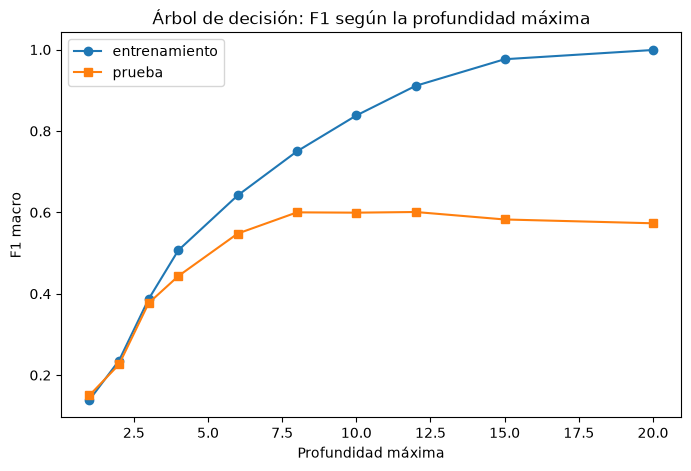

,F1 entrenamiento,F1 prueba
profundidad,,
1,0.139,0.150
2,0.236,0.226
3,0.387,0.377
4,0.507,0.443
6,0.642,0.548
8,0.750,0.600
10,0.838,0.599
12,0.911,0.601
15,0.976,0.583


In [14]:
filas = []
for profundidad in PROFUNDIDADES:
    arbol_p = DecisionTreeClassifier(max_depth=profundidad, random_state=SEMILLA).fit(X_entr, y_entr)
    filas.append({
        "profundidad": profundidad,
        "F1 entrenamiento": f1_score(y_entr, arbol_p.predict(X_entr), average="macro"),
        "F1 prueba": f1_score(y_prueba, arbol_p.predict(X_prueba), average="macro"),
    })
tabla_profundidad = pd.DataFrame(filas).set_index("profundidad")

fig, eje = plt.subplots(figsize=(8, 5))
eje.plot(tabla_profundidad.index, tabla_profundidad["F1 entrenamiento"], "o-", label="entrenamiento")
eje.plot(tabla_profundidad.index, tabla_profundidad["F1 prueba"], "s-", label="prueba")
eje.set(title="Árbol de decisión: F1 según la profundidad máxima", xlabel="Profundidad máxima", ylabel="F1 macro")
eje.legend()
plt.show()
tabla_profundidad.round(3)

#### Consigna 2.3 · Verificación: ¿dónde deja de mejorar?

Mirando **solo el gráfico**, anotá la profundidad a partir de la cual el F1 de prueba deja de mejorar. Después pedí que se calcule desde la tabla.

**Se espera:** tu lectura del gráfico y la profundidad con mayor F1 de prueba según la tabla. Si no coinciden exactamente, ¿cuánto difieren los F1 de prueba entre esas profundidades?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Buscá la profundidad donde la curva de prueba tiene su máximo; pandas tiene una función que devuelve la posición del máximo de una columna.

</details>

In [15]:
mejor_profundidad = tabla_profundidad["F1 prueba"].idxmax()
print(f"Profundidad con mayor F1 de prueba: {mejor_profundidad} (F1 = {tabla_profundidad.loc[mejor_profundidad, 'F1 prueba']:.3f})")

Profundidad con mayor F1 de prueba: 12 (F1 = 0.601)


#### Consigna 2.4 · ¿Qué píxeles mira el bosque?

El bosque registra cuánto usó cada columna para decidir (su **importancia**). Como cada columna es un píxel de un canal, la importancia se puede volver a dibujar como una imagen de 28 × 28.

**Se espera:** una figura con dos paneles: la imagen promedio de la submuestra de entrenamiento y un mapa de calor de 28 × 28 con la importancia de cada píxel (sumando los tres canales). ¿Dónde se concentra la importancia? ¿Tiene sentido mirando las imágenes?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Las importancias del bosque son un arreglo de 2352 valores, en el mismo orden en que se aplanaron las imágenes: se pueden volver a dar forma de 28 × 28 × 3 y sumar sobre el último eje.

</details>

> **Prompt de referencia (docente)**
>
> Con `bosque.feature_importances_`, armá un mapa de 28 × 28 sumando la importancia de los 3 canales de cada píxel. Hacé una figura con la imagen promedio de `imagenes_entr` a la izquierda y el mapa de importancia a la derecha, con barra de color.

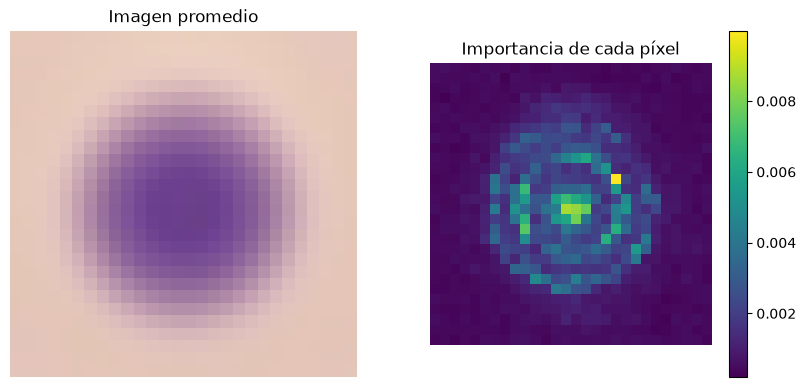

In [16]:
importancia = bosque.feature_importances_.reshape(28, 28, 3).sum(axis=2)
imagen_promedio = imagenes_entr.mean(axis=0).astype(np.uint8)

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5))
ejes[0].imshow(imagen_promedio)
ejes[0].set_title("Imagen promedio")
mapa = ejes[1].imshow(importancia, cmap="viridis")
ejes[1].set_title("Importancia de cada píxel")
fig.colorbar(mapa, ax=ejes[1])
for eje in ejes:
    eje.axis("off")
plt.show()

#### Interpretación

- El **árbol sin límite** crece hasta una profundidad de 21, con 700 hojas, y también memoriza (F1 de entrenamiento 1,000), pero en prueba es el peor de los tres: 0,574.
- El **bosque** memoriza igual (1,000) y aun así generaliza mucho mejor: 0,794 en prueba, contra 0,704 de la regresión logística. Cada árbol se equivoca de una manera distinta y, al votar, esos errores se compensan.
- **Curva por profundidad:** el F1 de entrenamiento sube sin parar, de 0,14 a 1,00. El de prueba sube hasta cerca de 0,60 en profundidad 8, se queda ahí hasta 12 (0,599 a 0,601) y baja un poco después (0,573 en profundidad 20). Es la misma forma que el error por grado del polinomio del módulo 7, aunque acá la caída es suave.
- La tabla marca la profundidad 12 como la mejor, pero la diferencia con la profundidad 8 es de una milésima: en la práctica, **a partir de 8 el árbol ya no mejora**, solo memoriza.
- **Importancia de los píxeles:** se concentra en un anillo y en el centro de la imagen, que es donde están el borde y el núcleo de la célula. Las esquinas, donde solo hay glóbulos rojos de fondo, casi no se usan. Tiene sentido: el tamaño de la célula y la forma de su núcleo son de lo que más distingue a los tipos celulares.

## Bloque 3 · Redes neuronales y curva de pérdida (25 min)

**Producto:** la curva de pérdida con la época de parada marcada.

Una **red neuronal** como la del módulo 2: capas de neuronas que transforman los 2352 valores de entrada hasta dar una probabilidad para cada tipo celular. Se entrena por **épocas**: en cada época recorre todos los datos de entrenamiento y ajusta sus pesos para reducir la **pérdida**, una medida de cuán lejos están sus probabilidades de las respuestas correctas.

**Una tercera partición: validación.** En el bloque 2 elegimos la profundidad mirando el F1 de **prueba**. Eso es hacer un poco de trampa: si usamos prueba para tomar decisiones, deja de ser una medición independiente. Para decidir (cuándo parar, qué profundidad usar) se usa la partición de **validación**, y prueba se reserva para el informe final.

**Ejemplo resuelto.** Una red con una capa oculta de 100 neuronas, entrenada `EPOCAS` épocas con los datos estandarizados. La curva muestra la pérdida en entrenamiento, época a época.

F1 macro · entrenamiento: 1.000 · prueba: 0.793


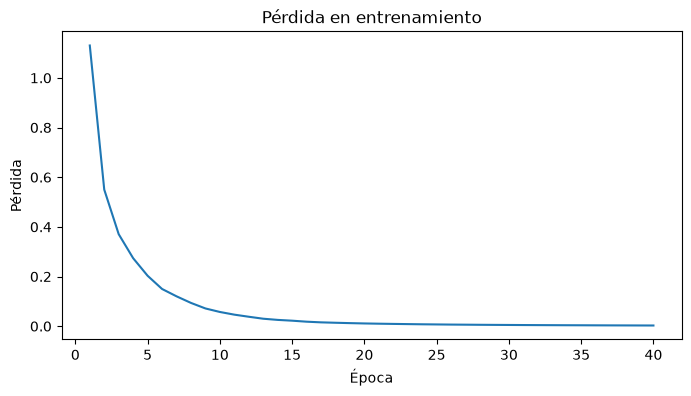

In [17]:
red = MLPClassifier(NEURONAS, max_iter=EPOCAS, random_state=SEMILLA).fit(X_entr_est, y_entr)

f1_entr = f1_score(y_entr, red.predict(X_entr_est), average="macro")
f1_prueba = f1_score(y_prueba, red.predict(X_prueba_est), average="macro")
print(f"F1 macro · entrenamiento: {f1_entr:.3f} · prueba: {f1_prueba:.3f}")
resultados.append({"modelo": f"red {NEURONAS}, {EPOCAS} épocas", "F1 entrenamiento": f1_entr, "F1 prueba": f1_prueba})

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(range(1, len(red.loss_curve_) + 1), red.loss_curve_)
eje.set(title="Pérdida en entrenamiento", xlabel="Época", ylabel="Pérdida")
plt.show()

#### Consigna 3.1 · La pérdida en validación

La curva del ejemplo solo dice cuánto aprendió la red sobre los datos que ya vio. Entrená una red igual, **de a una época por vez**, y después de cada época anotá la pérdida en entrenamiento y en validación, y el F1 en validación.

**Se espera:** un gráfico con las dos curvas de pérdida en función de la época. ¿Bajan juntas todo el tiempo?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

La red de scikit-learn tiene un método para entrenar de a una época (`partial_fit`); la primera vez hay que decirle cuáles son todas las clases posibles. La pérdida que usa la red se calcula con `log_loss`, a partir de las probabilidades que da `predict_proba`.

</details>

> **Prompt de referencia (docente)**
>
> Creá una `MLPClassifier(NEURONAS, random_state=SEMILLA)` llamada `red_epocas`. Durante `EPOCAS` épocas, entrenala con `partial_fit` sobre `X_entr_est` e `y_entr` (con todas las clases) y después de cada época guardá en `tabla_epocas` la pérdida (`log_loss`) en entrenamiento y en `X_val_est`, y el F1 macro en validación. Graficá las dos curvas de pérdida.

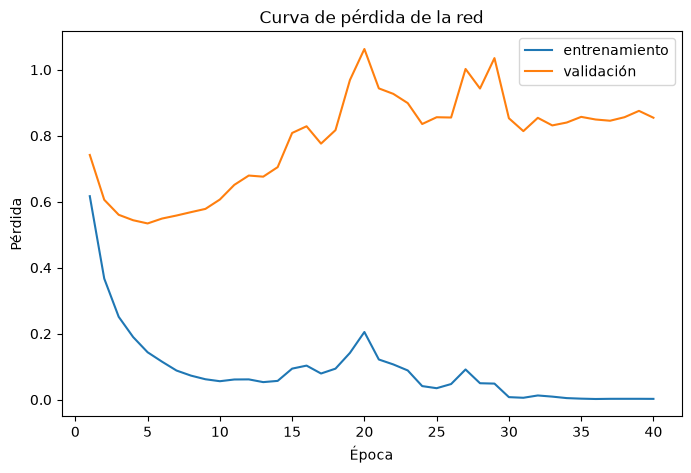

In [18]:
red_epocas = MLPClassifier(NEURONAS, random_state=SEMILLA)
clases = np.arange(len(TIPOS_CELULARES))

filas = []
for epoca in range(1, EPOCAS + 1):
    red_epocas.partial_fit(X_entr_est, y_entr, classes=clases)  # una época más de entrenamiento
    filas.append({
        "época": epoca,
        "pérdida entrenamiento": log_loss(y_entr, red_epocas.predict_proba(X_entr_est), labels=clases),
        "pérdida validación": log_loss(y_val, red_epocas.predict_proba(X_val_est), labels=clases),
        "F1 validación": f1_score(y_val, red_epocas.predict(X_val_est), average="macro"),
    })
tabla_epocas = pd.DataFrame(filas).set_index("época")

fig, eje = plt.subplots(figsize=(8, 5))
eje.plot(tabla_epocas.index, tabla_epocas["pérdida entrenamiento"], label="entrenamiento")
eje.plot(tabla_epocas.index, tabla_epocas["pérdida validación"], label="validación")
eje.set(title="Curva de pérdida de la red", xlabel="Época", ylabel="Pérdida")
eje.legend()
plt.show()

#### Consigna 3.2 · Verificación: ¿cuándo había que parar?

Ubicá **en el gráfico** la época en que la pérdida de validación es mínima. Después pedí que se calcule desde `tabla_epocas` y que se marque con una línea vertical.

**Se espera:** la época del mínimo, la pérdida y el F1 de validación en esa época y en la última, y el gráfico con la línea vertical. Compará: ¿cuánto cambió la pérdida de validación entre el mínimo y el final? ¿Y el F1?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Es la misma idea que en la consigna 2.3, pero ahora se busca un mínimo. Una línea vertical se dibuja con `axvline`.

</details>

> **Prompt de referencia (docente)**
>
> Calculá en `epoca_minima` la época con menor pérdida de validación en `tabla_epocas`. Imprimí la pérdida y el F1 de validación en esa época y en la última, y repetí el gráfico de pérdidas con una línea vertical punteada en `epoca_minima`.

       pérdida validación  F1 validación
época                                   
5                   0.534          0.780
40                  0.855          0.801


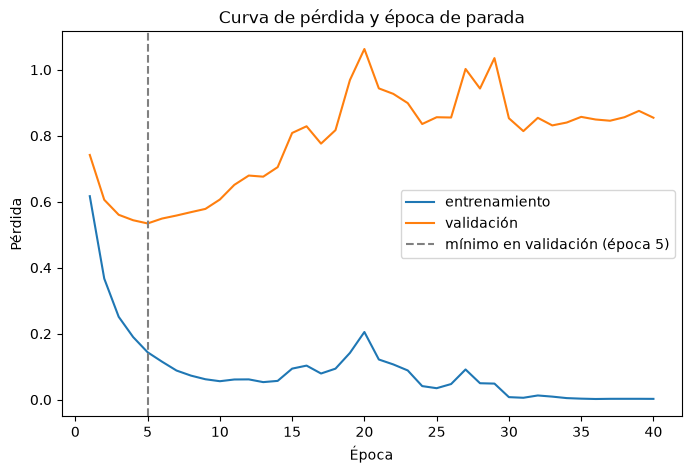

In [19]:
epoca_minima = tabla_epocas["pérdida validación"].idxmin()
print(tabla_epocas.loc[[epoca_minima, EPOCAS], ["pérdida validación", "F1 validación"]].round(3))

fig, eje = plt.subplots(figsize=(8, 5))
eje.plot(tabla_epocas.index, tabla_epocas["pérdida entrenamiento"], label="entrenamiento")
eje.plot(tabla_epocas.index, tabla_epocas["pérdida validación"], label="validación")
eje.axvline(epoca_minima, color="gray", linestyle="--", label=f"mínimo en validación (época {epoca_minima})")
eje.set(title="Curva de pérdida y época de parada", xlabel="Época", ylabel="Pérdida")
eje.legend()
plt.show()

#### Consigna 3.3 · Parada temprana

La red de scikit-learn puede detenerse sola: separa una parte de los datos de entrenamiento como validación interna y para cuando deja de mejorar. Entrená una red así y comparala con la del ejemplo.

**Se espera:** cuántas épocas entrenó y su F1 en entrenamiento y en prueba, anotados en `resultados`. ¿Paró cerca de la época que encontraste en la consigna 3.2?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Buscá en la documentación de `MLPClassifier` el parámetro que activa la parada temprana. La cantidad de épocas que entrenó queda guardada en el modelo.

</details>

> **Prompt de referencia (docente)**
>
> Entrená una `MLPClassifier(NEURONAS, early_stopping=True, random_state=SEMILLA)` llamada `red_temprana` con `X_entr_est` e `y_entr`. Imprimí cuántas épocas entrenó (`n_iter_`) y su F1 macro en entrenamiento y en prueba, y agregalo a `resultados`.

In [20]:
red_temprana = MLPClassifier(NEURONAS, early_stopping=True, random_state=SEMILLA).fit(X_entr_est, y_entr)

f1_entr = f1_score(y_entr, red_temprana.predict(X_entr_est), average="macro")
f1_prueba = f1_score(y_prueba, red_temprana.predict(X_prueba_est), average="macro")
print(f"Épocas entrenadas: {red_temprana.n_iter_}")
print(f"F1 macro · entrenamiento: {f1_entr:.3f} · prueba: {f1_prueba:.3f}")
resultados.append({"modelo": f"red {NEURONAS}, parada temprana", "F1 entrenamiento": f1_entr, "F1 prueba": f1_prueba})

Épocas entrenadas: 23
F1 macro · entrenamiento: 0.980 · prueba: 0.789


#### Consigna 3.4 · ¿Y si no estandarizamos?

Entrená la misma red del ejemplo, con la misma cantidad de épocas, pero con `X_entr` **sin estandarizar**. Compará las dos curvas de pérdida en entrenamiento.

**Se espera:** un gráfico con las dos curvas (con y sin estandarizar) y el F1 de prueba de cada red. ¿Cuál aprende más rápido?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

La curva de pérdida en entrenamiento queda guardada en el modelo después de entrenarlo, como en el ejemplo resuelto.

</details>

> **Prompt de referencia (docente)**
>
> Entrená una `MLPClassifier(NEURONAS, max_iter=EPOCAS, random_state=SEMILLA)` llamada `red_sin_est` con `X_entr` (sin estandarizar). Graficá su `loss_curve_` junto a la de `red` e imprimí el F1 macro de prueba de las dos.

F1 macro de prueba · con estandarizar: 0.793 · sin estandarizar: 0.718


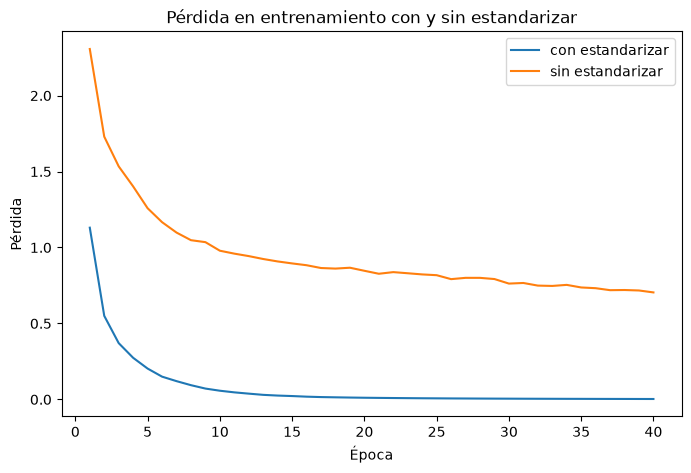

In [21]:
red_sin_est = MLPClassifier(NEURONAS, max_iter=EPOCAS, random_state=SEMILLA).fit(X_entr, y_entr)

print(f"F1 macro de prueba · con estandarizar: {f1_score(y_prueba, red.predict(X_prueba_est), average='macro'):.3f}"
      f" · sin estandarizar: {f1_score(y_prueba, red_sin_est.predict(X_prueba), average='macro'):.3f}")

fig, eje = plt.subplots(figsize=(8, 5))
eje.plot(range(1, len(red.loss_curve_) + 1), red.loss_curve_, label="con estandarizar")
eje.plot(range(1, len(red_sin_est.loss_curve_) + 1), red_sin_est.loss_curve_, label="sin estandarizar")
eje.set(title="Pérdida en entrenamiento con y sin estandarizar", xlabel="Época", ylabel="Pérdida")
eje.legend()
plt.show()

#### Interpretación

- La red de 100 neuronas, entrenada 40 épocas, llega a un F1 de 1,000 en entrenamiento y de 0,793 en prueba: casi igual que el bosque.
- **La curva de pérdida muestra el sobreajuste con claridad.** La pérdida de validación baja hasta su mínimo en la **época 5** (0,534) y después sube: termina en 0,855 en la época 40, con picos cercanos a 1,06. Mientras tanto, la de entrenamiento llega casi a 0.
- **El F1 cuenta otra historia:** en validación pasa de 0,780 en la época 5 a 0,801 en la 40. La red sigue acertando más o menos lo mismo, pero se vuelve **demasiado segura**: cuando se equivoca, asigna probabilidades muy altas a la clase incorrecta, y la pérdida castiga justamente eso. El F1 solo mira qué clase eligió la red; la pérdida mira también con cuánta confianza la eligió.
- La **parada temprana** entrenó 23 épocas, con un F1 de 0,980 en entrenamiento y de 0,789 en prueba: memoriza menos y prueba casi no cambia. No se detuvo en la época 5 porque su criterio interno es la exactitud (no la pérdida) sobre un 10 % de los datos de entrenamiento, y espera 10 épocas sin mejora antes de parar.
- **Sin estandarizar,** la red aprende mucho más lento: después de 40 épocas su pérdida de entrenamiento todavía ronda 0,70, contra casi 0 con datos estandarizados, y su F1 de prueba baja de 0,793 a 0,718. Para una red, estandarizar sí importa.

## Bloque 4 · PCA y ablación (25 min)

**Producto:** una figura de PCA y una tabla de ablación.

Cada imagen tiene 2352 valores, pero muchos están correlacionados: píxeles vecinos se parecen, y los tres canales de un mismo píxel también. El **análisis de componentes principales (PCA)** busca unas pocas direcciones, combinaciones de todos los píxeles, que resumen la mayor parte de la variación entre imágenes.

Todos los píxeles están en la misma escala (de 0 a 1), así que para PCA **no hace falta estandarizar**: usamos `X_entr`.

Una **ablación** consiste en quitar una pieza del análisis y medir cuánto empeora el resultado. Así se averigua qué parte de la información es la que importa.

**Ejemplo resuelto.** Las 5000 imágenes de entrenamiento proyectadas sobre las dos primeras componentes principales, con un color por tipo celular.

Varianza explicada por cada componente: [0.268 0.102]


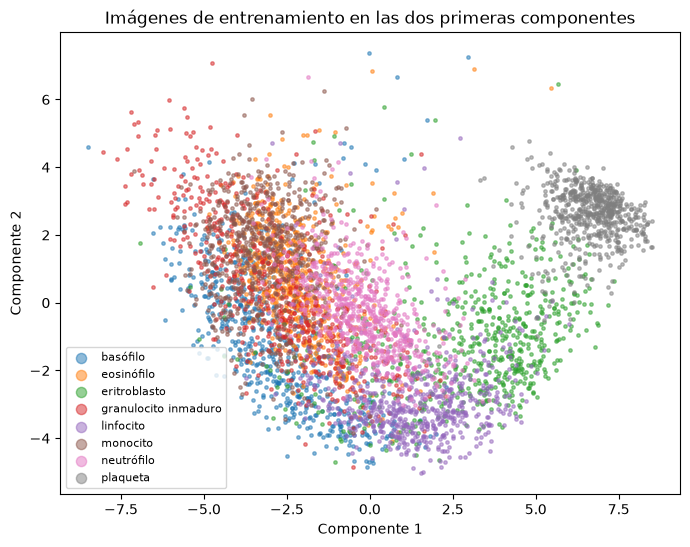

In [22]:
pca_2 = PCA(n_components=2, random_state=SEMILLA).fit(X_entr)
proyeccion = pca_2.transform(X_entr)
print("Varianza explicada por cada componente:", pca_2.explained_variance_ratio_.round(3))

fig, eje = plt.subplots(figsize=(8, 6))
for tipo, nombre in enumerate(TIPOS_CELULARES):
    de_este_tipo = y_entr == tipo
    eje.scatter(proyeccion[de_este_tipo, 0], proyeccion[de_este_tipo, 1], s=6, alpha=0.5, label=nombre)
eje.set(title="Imágenes de entrenamiento en las dos primeras componentes", xlabel="Componente 1", ylabel="Componente 2")
eje.legend(markerscale=3, fontsize=8)
plt.show()

#### Consigna 4.1 · Verificación: ¿cuántas componentes hacen falta?

Calculá la varianza explicada **acumulada** con hasta 200 componentes y graficala. Mirando **solo el gráfico**, anotá cuántas componentes hacen falta para explicar el 80 % y el 90 % de la varianza. Después pedí que se calcule.

**Se espera:** un gráfico de la varianza acumulada en función de la cantidad de componentes, con líneas horizontales en 0,8 y 0,9, y los dos números calculados. Tu lectura y el cálculo deberían diferir en pocas componentes.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

PCA guarda la fracción de varianza que explica cada componente; la acumulada es la suma acumulada de esas fracciones.

</details>

> **Prompt de referencia (docente)**
>
> Ajustá un `PCA(n_components=200, random_state=SEMILLA)` con `X_entr` y graficá la suma acumulada de `explained_variance_ratio_`, con líneas horizontales en 0,8 y 0,9. Imprimí cuántas componentes hacen falta para llegar al 80 % y al 90 %.

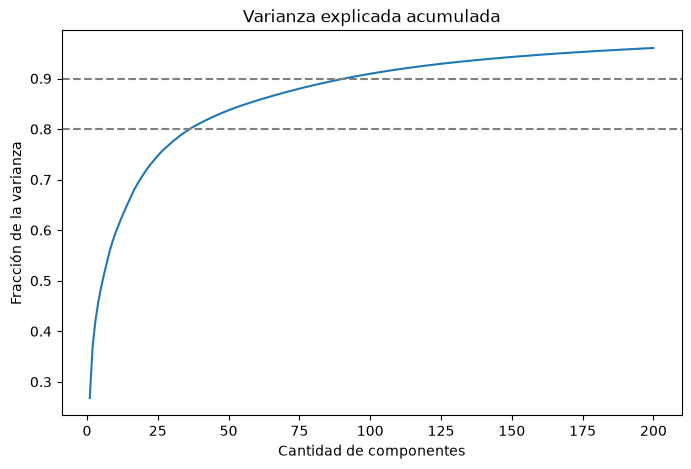

Para explicar el 80% de la varianza hacen falta 37 componentes
Para explicar el 90% de la varianza hacen falta 91 componentes


In [23]:
pca_200 = PCA(n_components=200, random_state=SEMILLA).fit(X_entr)
acumulada = np.cumsum(pca_200.explained_variance_ratio_)

fig, eje = plt.subplots(figsize=(8, 5))
eje.plot(range(1, len(acumulada) + 1), acumulada)
for nivel in [0.8, 0.9]:
    eje.axhline(nivel, color="gray", linestyle="--")
eje.set(title="Varianza explicada acumulada", xlabel="Cantidad de componentes", ylabel="Fracción de la varianza")
plt.show()

for nivel in [0.8, 0.9]:
    print(f"Para explicar el {nivel:.0%} de la varianza hacen falta {np.argmax(acumulada >= nivel) + 1} componentes")

#### Consigna 4.2 · Ablación del color

Convertí las imágenes a escala de grises (el promedio de los tres canales de cada píxel), mostrá algunas y entrená una regresión logística como la del bloque 1 con ellas.

**Se espera:** una grilla con las mismas imágenes de la consigna 1.1 en gris (una por tipo celular basta) y el F1 macro de prueba de la regresión logística en gris, comparado con el de color. Mirando las imágenes: ¿qué información se pierde?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

El promedio de los tres canales se calcula sobre el último eje de las imágenes. Después hay que aplanar y estandarizar como en el bloque 1, ahora con 784 columnas en lugar de 2352.

</details>

> **Prompt de referencia (docente)**
>
> Convertí `imagenes_entr` e `imagenes_prueba` a gris promediando los 3 canales (`imagenes_gris_entr`, `imagenes_gris_prueba`). Mostrá con `mostrar_imagenes` la primera imagen de cada tipo celular en color y en gris. Después aplaná las imágenes grises dividiendo por 255, estandarizalas con un `StandardScaler` ajustado en entrenamiento, entrená una `LogisticRegression(max_iter=1000)` y guardá su F1 macro de prueba en `f1_gris`.

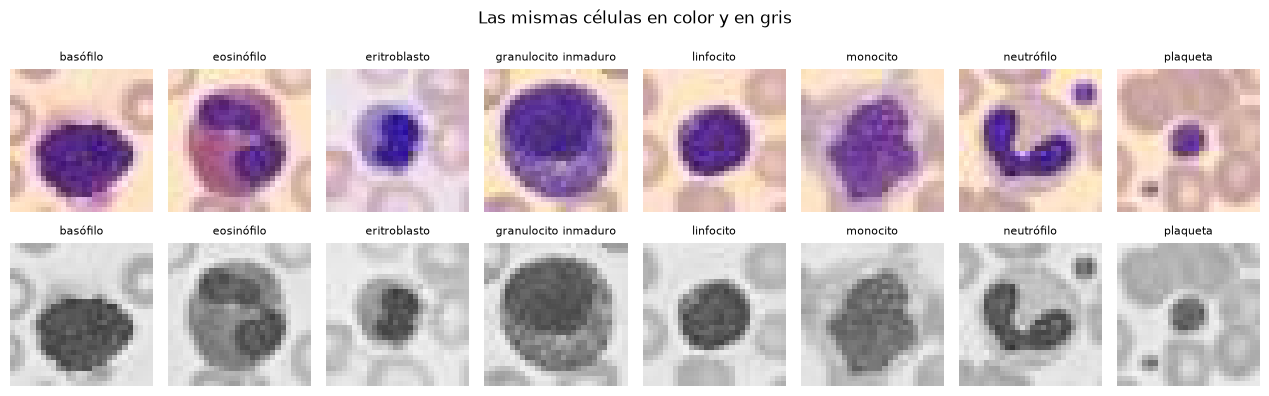

F1 macro de prueba · color: 0.704 · gris: 0.551


In [24]:
imagenes_gris_entr = imagenes_entr.mean(axis=3)      # promedio de rojo, verde y azul
imagenes_gris_prueba = imagenes_prueba.mean(axis=3)

# Verificación visual: la primera imagen de cada tipo, en color y en gris
primeras = [np.flatnonzero(y_entr == tipo)[0] for tipo in range(len(TIPOS_CELULARES))]
mostrar_imagenes(list(imagenes_entr[primeras]) + list(imagenes_gris_entr[primeras]),
                 TIPOS_CELULARES * 2, titulo_figura="Las mismas células en color y en gris")

X_gris_entr = imagenes_gris_entr.reshape(len(imagenes_gris_entr), -1) / 255
X_gris_prueba = imagenes_gris_prueba.reshape(len(imagenes_gris_prueba), -1) / 255
estandarizador_gris = StandardScaler().fit(X_gris_entr)
logistica_gris = LogisticRegression(max_iter=1000).fit(estandarizador_gris.transform(X_gris_entr), y_entr)

f1_color = f1_score(y_prueba, prediccion_logistica, average="macro")
f1_gris = f1_score(y_prueba, logistica_gris.predict(estandarizador_gris.transform(X_gris_prueba)), average="macro")
print(f"F1 macro de prueba · color: {f1_color:.3f} · gris: {f1_gris:.3f}")

#### Consigna 4.3 · Ablación de componentes

En lugar de darle a la regresión logística los 2352 valores de cada imagen, dale solo las primeras componentes principales. Probá con cada cantidad de `COMPONENTES`.

**Se espera:** una tabla `tabla_ablacion` con el F1 macro de prueba de la regresión logística en cada versión: con todas las columnas en color (bloque 1), en gris (consigna 4.2) y con cada cantidad de componentes principales. ¿Con cuántas componentes se recupera casi todo el F1?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Se pueden encadenar los pasos en un *pipeline*: primero PCA con la cantidad de componentes, después la regresión logística. Igual que el estandarizador, PCA se ajusta solo con los datos de entrenamiento.

</details>

> **Prompt de referencia (docente)**
>
> Para cada valor de `COMPONENTES`, armá un pipeline con `PCA(n_components=k, random_state=SEMILLA)`, `StandardScaler()` y `LogisticRegression(max_iter=1000)`, entrenalo con `X_entr` e `y_entr` y calculá el F1 macro de prueba. Armá `tabla_ablacion` con una fila por versión: «color, 2352 columnas» (F1 de `prediccion_logistica`), «gris, 784 columnas» (`f1_gris`) y una fila por cantidad de componentes.

In [25]:
filas = [
    {"versión": "color, 2352 columnas", "F1 prueba": f1_color},
    {"versión": "gris, 784 columnas", "F1 prueba": f1_gris},
]
for k in COMPONENTES:
    modelo_pca = make_pipeline(PCA(n_components=k, random_state=SEMILLA), StandardScaler(),
                               LogisticRegression(max_iter=1000)).fit(X_entr, y_entr)
    filas.append({"versión": f"color, {k} componentes principales",
                  "F1 prueba": f1_score(y_prueba, modelo_pca.predict(X_prueba), average="macro")})
tabla_ablacion = pd.DataFrame(filas).set_index("versión")
tabla_ablacion.round(3)

,F1 prueba
versión,
"color, 2352 columnas",0.704
"gris, 784 columnas",0.551
"color, 2 componentes principales",0.522
"color, 10 componentes principales",0.620
"color, 50 componentes principales",0.700
"color, 200 componentes principales",0.758


#### Interpretación

- Las dos primeras componentes explican el 26,8 % y el 10,2 % de la varianza. En ese plano, las **plaquetas** forman un grupo aparte, eritroblastos y linfocitos quedan hacia un costado, y los tipos de células grandes (basófilo, eosinófilo, granulocito inmaduro, monocito, neutrófilo) se superponen.
- Para explicar el 80 % de la varianza hacen falta **37 componentes**; para el 90 %, **91**. Es mucho menos que las 2352 columnas originales.
- **Ablación del color:** en gris, el F1 de prueba de la regresión logística cae de 0,704 a **0,551**. Las imágenes en gris conservan la forma y el tamaño, pero pierden el tono de los gránulos. El tipo más afectado es el eosinófilo, cuyo recall baja de 0,87 a 0,51 al perder el anaranjado. Las plaquetas casi no cambian (de 0,98 a 0,95), porque se reconocen por el tamaño.
- **Ablación de componentes:** con 2 componentes el F1 es 0,522; con 10, 0,620; con 50, 0,700, prácticamente lo mismo que con las 2352 columnas. Con 200 componentes llega a **0,758, más que con todas las columnas**: descartar las direcciones de poca varianza elimina ruido y reduce el sobreajuste.
- Conclusión de la ablación: el color aporta mucho más que la mayoría de las columnas. Se pueden descartar más de 2000 de las 2352 sin perder nada, pero no se puede descartar el color.

## Bloque 5 · Agrupamiento con K-Means (25 min)

**Producto:** dos tablas de grupos frente a tipos celulares y una conclusión.

Hasta ahora, los modelos aprendieron **con** las etiquetas. **K-Means** no las usa: reparte las imágenes en *k* grupos de modo que cada imagen quede cerca del centro de su grupo. Recién al final comparamos los grupos con los tipos celulares, para ver si el agrupamiento «descubrió» algo que coincide con lo que definieron los patólogos.

Para medir esa coincidencia usamos el **índice de Rand ajustado (ARI)**: vale 0 si los grupos no tienen nada que ver con los tipos celulares (como si se hubieran repartido al azar) y 1 si coinciden exactamente.

Primero probamos con **4 tipos celulares bien distintos entre sí**; después, con los 8.

**Ejemplo resuelto.** Las imágenes de los 4 tipos contrastados (2500 de la submuestra), resumidas en `COMPONENTES_AGRUPAMIENTO` componentes principales. K-Means trabaja sobre esas componentes: es más rápido y descarta parte del ruido. Como en el bloque 4, no hace falta estandarizar.

In [26]:
codigos_contrastados = [TIPOS_CELULARES.index(nombre) for nombre in TIPOS_CELULARES if nombre in TIPOS_CONTRASTADOS]
seleccion_4 = np.isin(y_entr, codigos_contrastados)
X_4 = X_entr[seleccion_4]
y_4 = y_entr[seleccion_4]
imagenes_4 = imagenes_entr[seleccion_4]

componentes_4 = PCA(n_components=COMPONENTES_AGRUPAMIENTO, random_state=SEMILLA).fit_transform(X_4)
print(f"Imágenes de {', '.join(TIPOS_CONTRASTADOS)}: {len(y_4)}")

Imágenes de linfocito, monocito, neutrófilo, plaqueta: 2500


#### Consigna 5.1 · Cuatro grupos para cuatro tipos celulares

Agrupá `componentes_4` en 4 grupos con K-Means y compará los grupos con los tipos celulares.

**Se espera:** una tabla cruzada con una fila por tipo celular y una columna por grupo (cuántas imágenes de cada tipo cayeron en cada grupo), y el ARI. Si el agrupamiento coincide con los tipos, cada fila tiene casi todas sus imágenes en una sola columna.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

K-Means está en scikit-learn; conviene fijar la semilla y pedirle varias inicializaciones. pandas tiene una función para armar tablas cruzadas. El ARI está en `sklearn.metrics`.

</details>

> **Prompt de referencia (docente)**
>
> Agrupá `componentes_4` con `KMeans(n_clusters=4, n_init=10, random_state=SEMILLA)` y guardá los grupos en `grupos_4`. Mostrá una tabla cruzada de tipo celular (con nombres) contra grupo e imprimí el ARI entre `y_4` y `grupos_4`.

In [27]:
grupos_4 = KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit_predict(componentes_4)

print(f"ARI: {adjusted_rand_score(y_4, grupos_4):.2f}")
pd.crosstab(pd.Series([TIPOS_CELULARES[t] for t in y_4], name="tipo celular"),
            pd.Series(grupos_4, name="grupo"))

ARI: 0.71


grupo,0,1,2,3
tipo celular,,,,
linfocito,7,494,3,121
monocito,540,0,0,85
neutrófilo,70,22,0,533
plaqueta,0,1,623,1


#### Consigna 5.2 · Verificación: mirar los grupos

Un grupo es un conjunto de imágenes: hay que mirarlas. Mostrá 8 imágenes de cada grupo, elegidas al azar con la semilla.

**Se espera:** una grilla de 4 filas (una por grupo). ¿Cada fila se ve homogénea? ¿Coincide con lo que dice la tabla cruzada?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Para cada grupo, elegí 8 imágenes al azar entre las que tienen ese número de grupo, y pasalas a `mostrar_imagenes` con el número de grupo como título.

</details>

> **Prompt de referencia (docente)**
>
> Para cada grupo de `grupos_4`, elegí 8 imágenes al azar de `imagenes_4` (con un generador de NumPy con `SEMILLA`) y mostralas con `mostrar_imagenes`, con el título «grupo N».

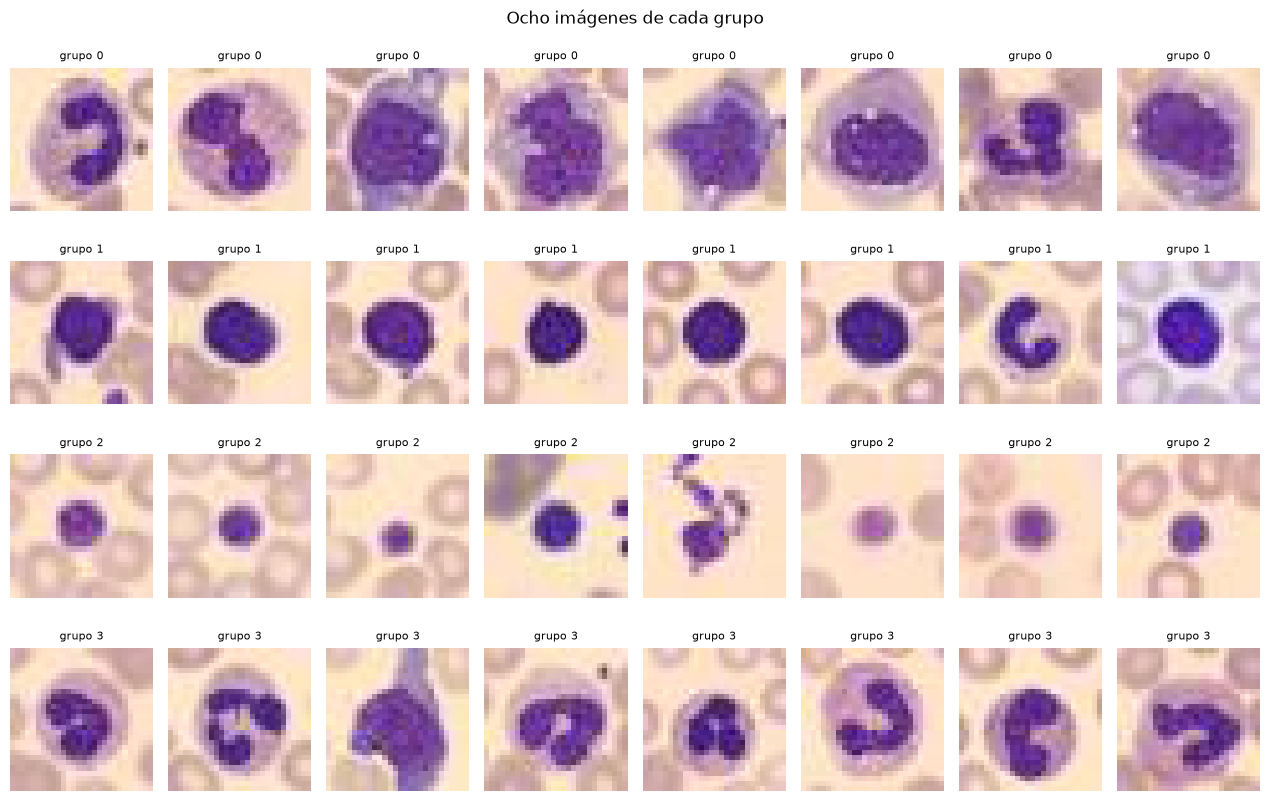

In [28]:
generador_grupos = np.random.default_rng(SEMILLA)
seleccion, titulos = [], []
for grupo in range(4):
    for indice in generador_grupos.choice(np.flatnonzero(grupos_4 == grupo), 8, replace=False):
        seleccion.append(imagenes_4[indice])
        titulos.append(f"grupo {grupo}")
mostrar_imagenes(seleccion, titulos, titulo_figura="Ocho imágenes de cada grupo")

#### Consigna 5.3 · ¿Cuántos grupos elegiría K-Means solo?

En la vida real no sabemos cuántos grupos hay. Dos criterios habituales: el **método del codo** (la inercia, es decir la distancia total de las imágenes al centro de su grupo, deja de bajar mucho a partir de cierto *k*) y la **silueta** (mide si cada imagen está más cerca de su grupo que del grupo vecino; cuanto mayor, mejor).

Calculá los dos para *k* entre 2 y `K_MAXIMO`, con las imágenes de los 4 tipos.

**Se espera:** dos gráficos, inercia y silueta en función de *k*. ¿Alguno de los dos señala claramente *k* = 4?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Es un ciclo sobre *k*: para cada valor, un K-Means nuevo. La inercia queda guardada en el modelo; la silueta está en `sklearn.metrics`.

</details>

> **Prompt de referencia (docente)**
>
> Para cada k entre 2 y `K_MAXIMO`, agrupá `componentes_4` con `KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)` y guardá la inercia y la silueta en `tabla_k`. Graficá las dos en función de k, en dos paneles.

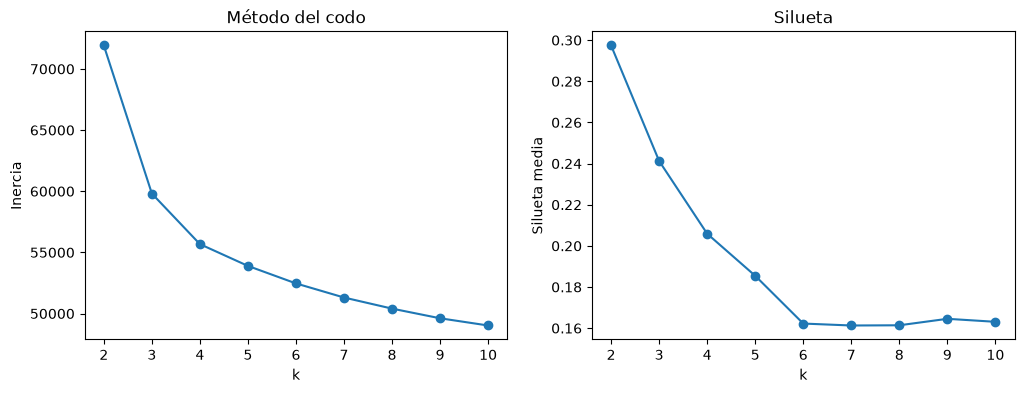

In [29]:
filas = []
for k in range(2, K_MAXIMO + 1):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(componentes_4)
    filas.append({"k": k, "inercia": kmeans.inertia_, "silueta": silhouette_score(componentes_4, kmeans.labels_)})
tabla_k = pd.DataFrame(filas).set_index("k")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(tabla_k.index, tabla_k["inercia"], "o-")
ejes[0].set(title="Método del codo", xlabel="k", ylabel="Inercia")
ejes[1].plot(tabla_k.index, tabla_k["silueta"], "o-")
ejes[1].set(title="Silueta", xlabel="k", ylabel="Silueta media")
plt.show()

#### Consigna 5.4 · Ahora con los 8 tipos celulares

Repetí el agrupamiento con **toda** la submuestra (los 8 tipos, 5000 imágenes): resumila en `COMPONENTES_AGRUPAMIENTO` componentes principales, agrupala en 8 grupos y comparala con los tipos celulares.

**Se espera:** la tabla cruzada de 8 × 8 y el ARI, comparado con el de los 4 tipos. ¿Qué tipos celulares siguen formando su propio grupo y cuáles se mezclan? Mostrá 8 imágenes de un grupo mezclado para ver por qué.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Son los mismos pasos que en el ejemplo resuelto y en las consignas 5.1 y 5.2, pero con `X_entr`, `y_entr` e `imagenes_entr`.

</details>

> **Prompt de referencia (docente)**
>
> Resumí `X_entr` en `COMPONENTES_AGRUPAMIENTO` componentes principales, agrupalas con `KMeans(n_clusters=8, n_init=10, random_state=SEMILLA)` en `grupos_8`, mostrá la tabla cruzada de tipo celular contra grupo e imprimí el ARI. Después elegí el grupo cuyo tipo celular más frecuente representa la menor fracción del grupo y mostrá 8 imágenes al azar de ese grupo con su tipo celular como título.

ARI con 8 tipos: 0.34 (con 4 tipos: 0.71)


grupo,0,1,2,3,4,5,6,7
tipo celular,,,,,,,,
basófilo,66,17,0,2,71,54,179,236
eosinófilo,63,67,1,2,6,76,319,91
eritroblasto,13,52,366,46,101,4,12,31
granulocito inmaduro,89,73,0,0,28,167,164,104
linfocito,13,36,138,1,374,1,1,61
monocito,117,17,0,0,0,280,170,41
neutrófilo,35,488,14,0,23,16,42,7
plaqueta,0,1,19,605,0,0,0,0


Grupo más mezclado: 0 (su tipo más frecuente es solo el 30% del grupo)


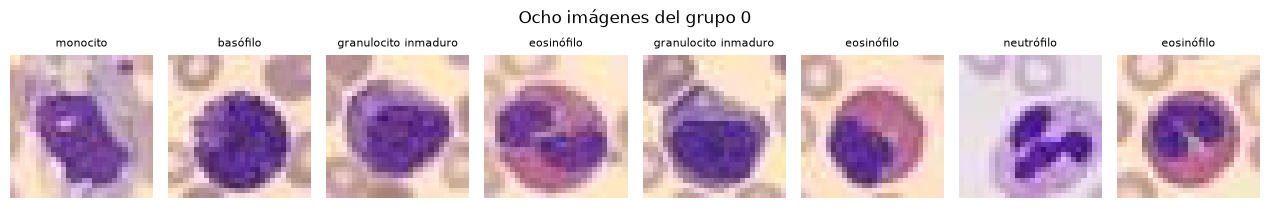

In [30]:
componentes_8 = PCA(n_components=COMPONENTES_AGRUPAMIENTO, random_state=SEMILLA).fit_transform(X_entr)
grupos_8 = KMeans(n_clusters=8, n_init=10, random_state=SEMILLA).fit_predict(componentes_8)

print(f"ARI con 8 tipos: {adjusted_rand_score(y_entr, grupos_8):.2f} (con 4 tipos: {adjusted_rand_score(y_4, grupos_4):.2f})")
tabla_cruzada_8 = pd.crosstab(pd.Series([TIPOS_CELULARES[t] for t in y_entr], name="tipo celular"),
                              pd.Series(grupos_8, name="grupo"))
display(tabla_cruzada_8)

# Grupo más mezclado: aquel donde el tipo más frecuente representa la menor fracción del grupo
pureza = tabla_cruzada_8.max() / tabla_cruzada_8.sum()
grupo_mezclado = pureza.idxmin()
print(f"Grupo más mezclado: {grupo_mezclado} (su tipo más frecuente es solo el {pureza.min():.0%} del grupo)")
muestra = np.random.default_rng(SEMILLA).choice(np.flatnonzero(grupos_8 == grupo_mezclado), 8, replace=False)
mostrar_imagenes(imagenes_entr[muestra], [TIPOS_CELULARES[y_entr[i]] for i in muestra],
                 titulo_figura=f"Ocho imágenes del grupo {grupo_mezclado}")

#### Interpretación

- **Con 4 tipos contrastados, el agrupamiento coincide bastante con los tipos celulares (ARI 0,71).** Cada tipo tiene la mayoría de sus imágenes en un grupo propio: 623 de 625 plaquetas, 540 monocitos, 533 neutrófilos y 494 linfocitos. La mezcla más grande es la de 121 linfocitos que caen en el grupo de los neutrófilos.
- **Las imágenes lo confirman:** cada grupo tiene un aspecto bastante homogéneo. Uno junta células chicas (plaquetas), otro núcleos redondos (linfocitos), otro núcleos segmentados (neutrófilos) y otro células grandes (monocitos), en el que se cuelan algunos neutrófilos.
- **Elegir k no es automático.** La inercia baja cada vez menos, sin un codo marcado. La silueta es máxima con k = 2 (0,30) y baja de ahí en adelante. Ninguno de los dos criterios señala claramente k = 4: sin saber de antemano cuántos tipos celulares hay, K-Means no lo habría descubierto solo.
- **Con los 8 tipos, la coincidencia cae a ARI 0,34.** Las plaquetas siguen en un grupo propio (605 de 625), y los neutrófilos (488), los linfocitos (374) y los eritroblastos (366) forman grupos reconocibles. En cambio, basófilos, eosinófilos, granulocitos inmaduros y monocitos se reparten entre varios grupos: en el más mezclado, el tipo más frecuente es apenas el 30 %.
- **Conclusión:** K-Means agrupa por parecido visual global: tamaño, color, forma del núcleo. Ese parecido coincide con nuestras categorías cuando los tipos celulares se ven claramente distintos, pero no cuando la diferencia está en detalles, como los gránulos o los lóbulos, que a 28 × 28 píxeles casi no se ven. Un agrupamiento no descubre por sí solo las categorías que definen los especialistas. Los clasificadores sí distinguen mejor esos tipos (F1 cercano a 0,79) porque aprenden **con** las etiquetas.

## Cierre (10 min)

**Producto:** el cuaderno completo y guardado.

**Ejemplo resuelto.** Todos los modelos de clasificación de la clase, con su F1 macro.

In [31]:
tabla_modelos = pd.DataFrame(resultados).set_index("modelo")
tabla_modelos["diferencia"] = tabla_modelos["F1 entrenamiento"] - tabla_modelos["F1 prueba"]
tabla_modelos.sort_values("F1 prueba", ascending=False).round(3)

,F1 entrenamiento,F1 prueba,diferencia
modelo,,,
bosque aleatorio,1.00,0.794,0.206
"red (100,), 40 épocas",1.00,0.793,0.207
"red (100,), parada temprana",0.98,0.789,0.191
regresión logística,1.00,0.704,0.296
árbol sin límite,1.00,0.574,0.426


#### Consigna final · Elegir y justificar un modelo

1. Pedile al asistente que explique, en lenguaje sencillo, la tabla `tabla_modelos` y que recomiende un modelo para clasificar estas imágenes.
2. **Verificá** la explicación contra la tabla: ¿cita bien los números? ¿Elige por el F1 de prueba y no por el de entrenamiento? ¿Tiene en cuenta la columna «diferencia»?
3. Escribí tu elección y justificala en tres o cuatro frases: qué métrica usaste, sobre qué datos, qué tiene de bueno o de malo el modelo y qué te dijo el bloque 5 sobre la dificultad de distinguir algunos tipos celulares.

**Tu elección y justificación:**

*...*